# EE66 - Homework 7 (Social Media Simulation)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- Transition Matrix and Initial State ---
A = np.array([
    [0.8, 0.3, 0.0, 0.4],
    [0.2, 0.7, 0.0, 0.1],
    [0.0, 0.0, 1.0, 0.4],
    [0.0, 0.0, 0.0, 0.1]
])

x0 = np.array([110, 60, 10, 140], dtype=float)

Let's quickly gut-check your work by printing the shapes of these `numpy` arrays.

In [6]:
print(f'A has shape {A.shape} and should be (4, 4)')
print(f'x0 has shape {x0.shape} and should be (4,)')

(4, 4) should be (4, 4)
(4,) should be (4,)


In [15]:
# --- Simulator Function ---
def simulate(A, x0, steps=5):
    '''
        simulate the state space for some time steps

        inputs are A and x0, whose first dimension should
        match, and a number of steps to run the simulation

        output is a single array of size (number of steps,
        dimension of each state / size of x0)
    '''

    xs = [x0]
    for _ in range(steps):
        x_next = A @ xs[-1]
        xs.append(x_next)

    return np.array(xs)


This part runs the simulator you wrote above. No code changes necessary!


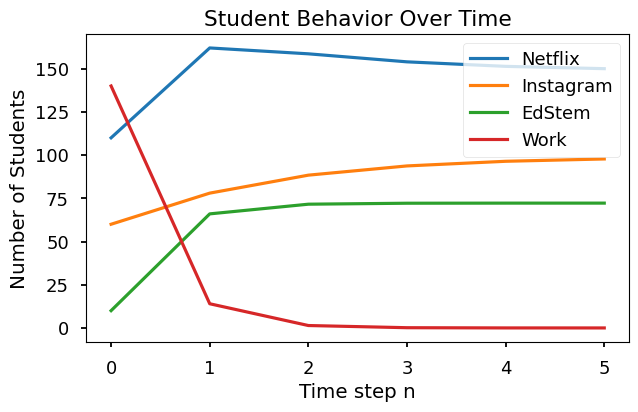

Total students (should be constant): [320. 320. 320. 320. 320. 320.]
Constant total = 320.0
Steady state vector x̂ = [1.500096e+02 9.776740e+01 7.222160e+01 1.400000e-03]
Proportions = [4.68780000e-01 3.05523125e-01 2.25692500e-01 4.37500000e-06]


In [16]:
# --- Part (d): Run Simulation ---
xs = simulate(A, x0)
n = np.arange(len(xs))

# Plot trajectories
plt.figure(figsize=(7,4))
plt.plot(n, xs[:,0], label='Netflix')
plt.plot(n, xs[:,1], label='Instagram')
plt.plot(n, xs[:,2], label='EdStem')
plt.plot(n, xs[:,3], label='Work')
plt.xlabel('Time step n')
plt.ylabel('Number of Students')
plt.title('Student Behavior Over Time')
plt.legend()
plt.show()

# Check conservation
S = xs.sum(axis=1)
print("Total students (should be constant):", S)
print("Constant total =", S[0])

x_hat = xs[-1]
print("Steady state vector x̂ =", x_hat)
print("Proportions =", x_hat / x_hat.sum())


Next write a function that creates the modified transition matrix as described in part (e).


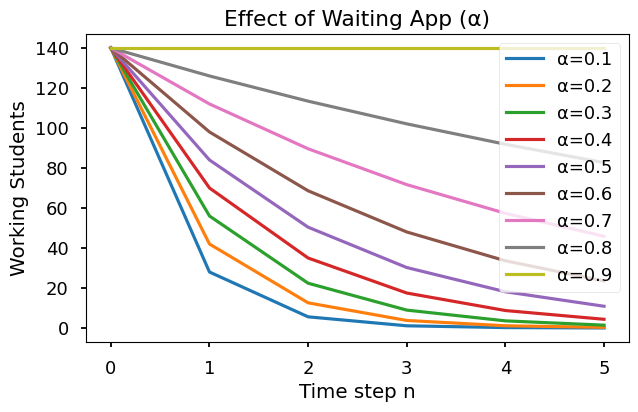

In [21]:
# --- Part (e): Waiting App (vary α) ---
def make_A_alpha(alpha):
    return np.array([
        [0.8, 0.3, 0.0, 0.4 - alpha/0.9 * 0.4],
        [0.2, 0.7, 0.0, 0.1 - alpha/0.9 * 0.1],
        [0.0, 0.0, 1.0, 0.4 - alpha/0.9 * 0.4],
        [0.0, 0.0, 0.0, 0.1 + alpha/0.9 * 0.9]
    ])


alphas = np.arange(0.1, 1.0, 0.1)
plt.figure(figsize=(7,4))
for alpha in alphas:
    xs_alpha = simulate(make_A_alpha(alpha), x0)
    plt.plot(xs_alpha[:,3], label=f'α={alpha:.1f}')
plt.xlabel('Time step n')
plt.ylabel('Working Students')
plt.title('Effect of Waiting App (α)')
plt.legend()
plt.show()


Next write a function that creates the modified transition matrix as described in part (f).

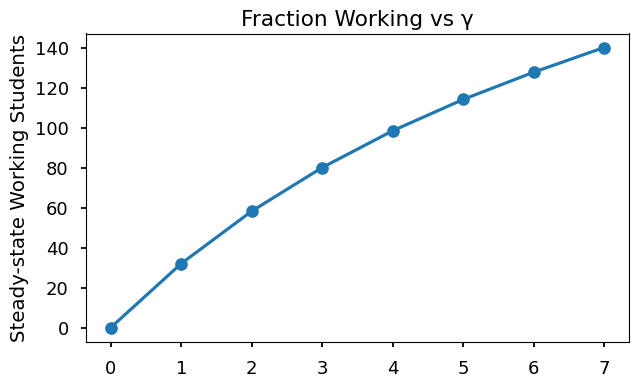

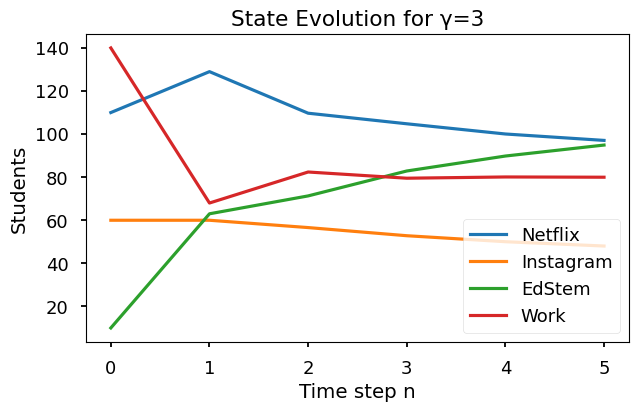

Steady-state proportions for γ=0.7:
[0.30335719 0.15010812 0.29659469 0.24994   ]


In [23]:
# --- Part (f): Blocking App (vary γ) ---
def make_A_gamma(gamma):
    return np.array([
        [0.8 - gamma / 10, 0.3, 0.0, 0.4],
        [0.2, 0.7 - gamma / 10, 0.0, 0.1],
        [0.0, 0.0, 1 - gamma / 10, 0.4],
        [gamma / 10, gamma / 10, gamma / 10, 0.1]
    ])

gammas = np.arange(0, 7.1, 1)
steady_W = []
for g in gammas:
    xs_g = simulate(make_A_gamma(g), x0)
    steady_W.append(xs_g[-1,3])

plt.figure(figsize=(7,4))
plt.plot(gammas, steady_W, marker='o')
plt.ylabel('Steady-state Working Students')
plt.title('Number of Working students vs γ')
plt.title('Fraction Working vs γ')
plt.show()

γ = 3
xs_gamma = simulate(make_A_gamma(γ), x0)
plt.figure(figsize=(7,4))
plt.plot(xs_gamma[:,0], label='Netflix')
plt.plot(xs_gamma[:,1], label='Instagram')
plt.plot(xs_gamma[:,2], label='EdStem')
plt.plot(xs_gamma[:,3], label='Work')
plt.xlabel('Time step n')
plt.ylabel('Students')
plt.title(f'State Evolution for γ={γ}')
plt.legend()
plt.show()

print("Steady-state proportions for γ=0.7:")
print(xs_gamma[-1] / xs_gamma[-1].sum())